<a href="https://colab.research.google.com/github/Sharu-052897/deep-learning/blob/main/NLP%20exp%209.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
VOCAB_SIZE = 10000

(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("IMDB dataset loaded successfully!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("First review:", X_train[0][:20])
print("First label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
IMDB dataset loaded successfully!
Training samples: 25000
Testing samples: 25000
First review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First label: 1


In [3]:
print("0 = Negative Review")
print("1 = Positive Review")

print("\nFirst 10 labels:")
print(y_train[:10])

0 = Negative Review
1 = Positive Review

First 10 labels:
[1 0 0 1 0 0 1 0 1 0]


In [4]:
MAX_LENGTH = 200

X_train = pad_sequences(
    X_train,
    maxlen=MAX_LENGTH,
    padding='post',
    truncating='post'
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_LENGTH,
    padding='post',
    truncating='post'
)

print("Sequence padding completed!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Sequence padding completed!
Training shape: (25000, 200)
Testing shape: (25000, 200)


In [5]:
print("Original sequence:")
print(X_train[0][:30])

print("\nPadded sequence:")
print(X_train[0][-30:])

Original sequence:
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480]

Padded sequence:
[  26  141    6  194 7486   18    4  226   22   21  134  476   26  480
    5  144   30 5535   18   51   36   28  224   92   25  104    4  226
   65   16]


In [6]:
model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=64,
        input_length=MAX_LENGTH
    ),

    LSTM(64),

    Dropout(0.5),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

model.summary()

print("LSTM NLP model created successfully!")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

LSTM NLP model created successfully!


In [7]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [8]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.5355 - loss: 0.6878 - val_accuracy: 0.5090 - val_loss: 0.6917
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5896 - loss: 0.6695 - val_accuracy: 0.6076 - val_loss: 0.6588
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6457 - loss: 0.6313 - val_accuracy: 0.6038 - val_loss: 0.6415
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5982 - loss: 0.6561 - val_accuracy: 0.5246 - val_loss: 0.6912
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5189 - loss: 0.6933 - val_accuracy: 0.5080 - val_loss: 0.6928


In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nTest Loss:", round(test_loss, 4))

print(
    "Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5068 - loss: 0.6928

Test Loss: 0.6928
Test Accuracy: 50.68 %


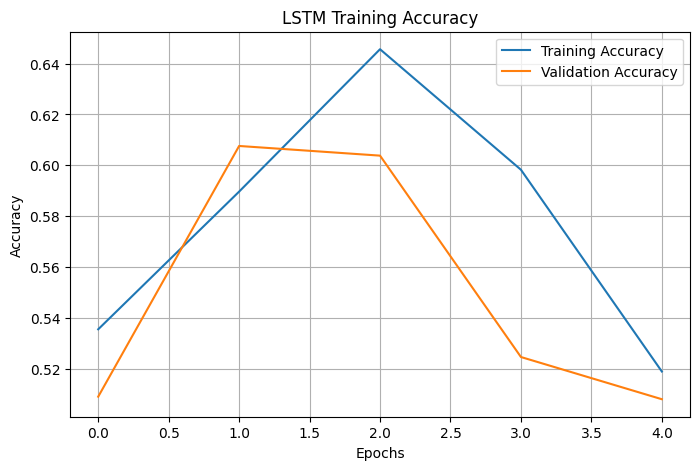

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("LSTM Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()
plt.show()

In [12]:
predictions = model.predict(
    X_test[:10],
    verbose=0
)

for i in range(10):

    sentiment = (
        "Positive" if predictions[i][0] >= 0.5
        else "Negative"
    )

    print(
        "Review", i + 1,
        "Predicted Sentiment:", sentiment,
        "| Actual:", "Positive" if y_test[i] == 1 else "Negative"
    )

Review 1 Predicted Sentiment: Positive | Actual: Negative
Review 2 Predicted Sentiment: Positive | Actual: Positive
Review 3 Predicted Sentiment: Positive | Actual: Positive
Review 4 Predicted Sentiment: Positive | Actual: Negative
Review 5 Predicted Sentiment: Positive | Actual: Positive
Review 6 Predicted Sentiment: Negative | Actual: Positive
Review 7 Predicted Sentiment: Positive | Actual: Positive
Review 8 Predicted Sentiment: Positive | Actual: Negative
Review 9 Predicted Sentiment: Negative | Actual: Negative
Review 10 Predicted Sentiment: Positive | Actual: Positive


In [13]:
word_index = imdb.get_word_index()

def predict_sentiment(review):

    words = review.lower().split()

    sequence = [
        word_index.get(word, 2) + 3
        for word in words
    ]

    sequence = pad_sequences(
        [sequence],
        maxlen=MAX_LENGTH,
        padding='post',
        truncating='post'
    )

    prediction = model.predict(sequence, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Sentiment: POSITIVE")
    else:
        print("Sentiment: NEGATIVE")

    print("Confidence:", round(float(prediction) * 100, 2), "%")


predict_sentiment(
    "This movie is wonderful and amazing. I really enjoyed it."
)

predict_sentiment(
    "This movie is boring and terrible. I did not like it."
)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Sentiment: POSITIVE
Confidence: 50.89 %
Sentiment: POSITIVE
Confidence: 51.06 %


In [14]:
print("========== NLP SENTIMENT ANALYSIS ==========")

print("Dataset: IMDB Movie Reviews")
print("Architecture: LSTM")
print("Embedding Dimension: 64")
print("Maximum Sequence Length:", MAX_LENGTH)
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))

print("============================================")

========== NLP SENTIMENT ANALYSIS ==========
Dataset: IMDB Movie Reviews
Architecture: LSTM
Embedding Dimension: 64
Maximum Sequence Length: 200
Training Samples: 25000
Testing Samples: 25000
Test Accuracy: 50.68 %
Test Loss: 0.6928
